# Speech recognition and summarization
Turn spoken English into a readable, timestamped transcript and a short summary. The default demo uses a short Marketplace audio clip provided with the [Dataquest solution](https://github.com/dataquestio/project-walkthroughs/tree/master/speech_recognition). Adapted from [Dataquest's guided project](https://www.dataquest.io/projects/build-a-speech-recognition-and-summarization-system/).

**Run all** to process the sample. To analyze your own audio, switch `AUDIO_SOURCE` to `"upload"` and rerun from Section 2. The notebook uses Vosk for speech recognition and FFmpeg to decode audio. It adds sentence breaks from speech pauses and offers an optional Hugging Face model to write an abstractive summary.

## 1. Install dependencies

In [ ]:
%pip -q install vosk==0.3.45

## 2. Load sample audio or upload a recording

In [1]:
from pathlib import Path
from urllib.request import urlretrieve
import os
import shutil

AUDIO_SOURCE = "sample"  # "sample" or "upload"
# Switch to marketplace_full.mp3 to use the longer course recording.
SAMPLE_NAME = "marketplace.mp3"
SAMPLE_BASE = "https://raw.githubusercontent.com/dataquestio/project-walkthroughs/master/speech_recognition/"
workdir = Path("speech_work")
workdir.mkdir(exist_ok=True)

if AUDIO_SOURCE == "sample":
    audio_path = workdir / SAMPLE_NAME
    if not audio_path.exists():
        urlretrieve(SAMPLE_BASE + SAMPLE_NAME, audio_path)
elif AUDIO_SOURCE == "upload":
    from google.colab import files
    uploaded = files.upload()
    if len(uploaded) != 1:
        raise ValueError("Upload exactly one audio file, such as an MP3 or WAV.")
    filename, content = next(iter(uploaded.items()))
    audio_path = workdir / Path(filename).name
    audio_path.write_bytes(content)
else:
    raise ValueError('Set AUDIO_SOURCE to "sample" or "upload".')

if not shutil.which("ffmpeg"):
    raise RuntimeError("Install FFmpeg or use a standard Colab runtime.")
print(f"Audio: {audio_path.name}")

Audio: marketplace.mp3


## 3. Transcribe in chunks
Decode to 16 kHz mono PCM and stream blocks through a single recognizer. Collect each completed segment and flush the recognizer at the end so words near the end are retained. The small English model defaults to CPU.

In [2]:
import json
import subprocess
import time
import wave
from vosk import KaldiRecognizer, Model, SetLogLevel

FRAME_RATE = 16000
MODEL_NAME = "vosk-model-small-en-us-0.15"
SetLogLevel(-1)
local_model = os.environ.get("SPEECH_VOSK_MODEL_PATH")
speech_model = Model(model_path=local_model) if local_model else Model(model_name=MODEL_NAME)

def transcribe(audio_path, model):
    wav_path = workdir / "normalized.wav"
    subprocess.run(
        ["ffmpeg", "-y", "-loglevel", "error", "-i", str(audio_path),
         "-ac", "1", "-ar", str(FRAME_RATE), "-c:a", "pcm_s16le", str(wav_path)],
        check=True, capture_output=True,
    )
    recognizer = KaldiRecognizer(model, FRAME_RATE)
    recognizer.SetWords(True)
    words = []
    with wave.open(str(wav_path), "rb") as audio:
        duration = audio.getnframes() / audio.getframerate()
        while block := audio.readframes(4000):
            if recognizer.AcceptWaveform(block):
                words.extend(json.loads(recognizer.Result()).get("result", []))
        words.extend(json.loads(recognizer.FinalResult()).get("result", []))
    if not words:
        raise ValueError("No recognizable English speech was found.")
    return words, duration

started = time.perf_counter()
words, duration = transcribe(audio_path, speech_model)
elapsed = time.perf_counter() - started
print(f"{duration:.1f} seconds of audio | {len(words):,} recognized words | {elapsed:.1f} seconds to transcribe")

46.0 seconds of audio | 142 recognized words | 4.7 seconds to transcribe


## 4. Make the transcript readable
Capitalize each segment and add a period. A pause of 0.65 seconds or a 32-word cap marks a new segment. These breaks are approximate, and the timestamp makes it easy to check words against the original recording.

In [3]:
def segment_transcript(words, pause_seconds=0.65, max_words=32):
    segments = []
    segment = []

    def finish(current):
        text = " ".join(word["word"] for word in current)
        return {"start": current[0]["start"], "end": current[-1]["end"],
                "text": text[0].upper() + text[1:] + "."}

    for word in words:
        if segment and (word["start"] - segment[-1]["end"] >= pause_seconds
                        or len(segment) >= max_words):
            segments.append(finish(segment))
            segment = []
        segment.append(word)
    if segment:
        segments.append(finish(segment))
    return segments

def timestamp(seconds):
    whole = int(seconds)
    return f"{whole // 60:02d}:{whole % 60:02d}"

segments = segment_transcript(words)
transcript = " ".join(item["text"] for item in segments)
for item in segments[:5]:
    print(f"[{timestamp(item['start'])}–{timestamp(item['end'])}] {item['text']}")

[00:00–00:09] The funny thing about the big economic news of the day the fed raising interest rates have a percentage point was that there was only really one bit of actual news in.
[00:09–00:20] The news and the interest rate increase wasn't it you know it was common i know it was common wall street news common businesses knew it was common so on and this.
[00:20–00:29] Fed day on this program something a little bit different j powell in his own words five of i'm his most used economic words from today's press conference where number one of.
[00:29–00:41] Course it's the biggie two percent inflation and inflation inflation inflation place in english dealing with inflation bells big worry that thing keeping him up at night price stability is the feds.
[00:41–00:45] Whole ballgame right now pal basically said as much to day or number two.


## 5. Produce a summary
The default extracts representative segments using TF-IDF. For longer recordings the selected passages are spread across the timeline. This mode quotes the transcript, so transcription errors can carry through. The optional FLAN-T5 mode rewrites those passages in its own words and should be checked against the transcript.

In [4]:
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer

SUMMARY_MODE = "extractive"  # "extractive" or "flan"
MAX_BULLETS = 4

def summarize_passages(segments, limit):
    if len(segments) <= limit:
        return segments
    passages = [item["text"] for item in segments]
    vectors = TfidfVectorizer(stop_words="english").fit_transform(passages)
    centroid_scores = np.asarray(vectors @ np.asarray(vectors.mean(axis=0)).ravel())
    bins = np.array_split(np.arange(len(segments)), limit)
    picked = [int(part[np.argmax(centroid_scores[part])]) for part in bins]
    return [segments[index] for index in picked]

key_passages = summarize_passages(segments, MAX_BULLETS)
if SUMMARY_MODE == "extractive":
    summary = "\n".join(f"- [{timestamp(item['start'])}] {item['text']}" for item in key_passages)
elif SUMMARY_MODE == "flan":
    from transformers import AutoModelForSeq2SeqLM, AutoTokenizer
    model_id = "google/flan-t5-small"
    tokenizer = AutoTokenizer.from_pretrained(model_id)
    summary_model = AutoModelForSeq2SeqLM.from_pretrained(model_id)
    context = " ".join(item["text"] for item in key_passages)
    prompt = "Summarize the main points of this transcript in three short sentences: " + context
    inputs = tokenizer(prompt, return_tensors="pt", truncation=True, max_length=512)
    tokens = summary_model.generate(**inputs, max_new_tokens=110, num_beams=4, do_sample=False)
    summary = tokenizer.decode(tokens[0], skip_special_tokens=True)
else:
    raise ValueError('Set SUMMARY_MODE to "extractive" or "flan".')

print(summary)

- [00:00] The funny thing about the big economic news of the day the fed raising interest rates have a percentage point was that there was only really one bit of actual news in.
- [00:20] Fed day on this program something a little bit different j powell in his own words five of i'm his most used economic words from today's press conference where number one of.
- [00:29] Course it's the biggie two percent inflation and inflation inflation inflation place in english dealing with inflation bells big worry that thing keeping him up at night price stability is the feds.
- [00:41] Whole ballgame right now pal basically said as much to day or number two.


For the optional FLAN-T5 mode, install the additional dependencies in a new code cell with `%pip install -q "transformers<5" sentencepiece`, then set `SUMMARY_MODE = "flan"` and rerun Section 5 onward.

## 6. Visualize and export

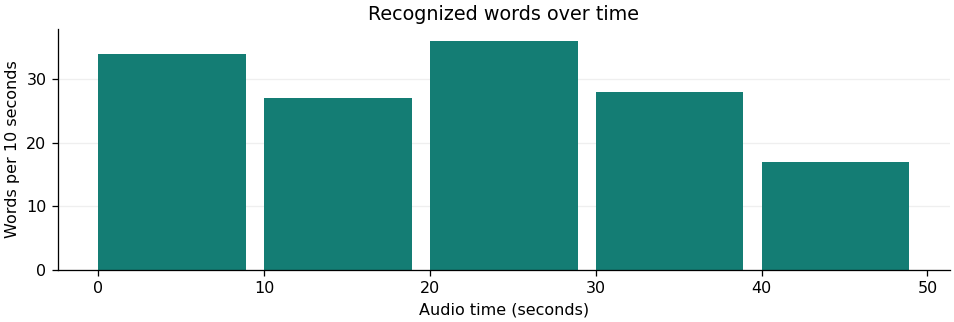

Exports: speech_results/transcript.txt, speech_results/summary.txt


In [5]:
import matplotlib.pyplot as plt

interval = 10 if duration < 180 else 60
edges = np.arange(0, duration + interval, interval)
if len(edges) < 2:
    edges = np.array([0, interval])
counts, _ = np.histogram([word["start"] for word in words], bins=edges)
minutes = duration >= 180
scale = 60 if minutes else 1
fig, ax = plt.subplots(figsize=(8.3, 2.8), layout="constrained")
ax.bar(edges[:-1] / scale, counts, width=interval / scale * 0.89, align="edge", color="#147D74")
ax.set(title="Recognized words over time", ylabel=f"Words per {interval} seconds",
       xlabel="Audio time (minutes)" if minutes else "Audio time (seconds)")
ax.grid(axis="y", alpha=.2)
ax.set_axisbelow(True)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

output_dir = Path("speech_results")
output_dir.mkdir(exist_ok=True)
timestamped = "\n".join(f"[{timestamp(item['start'])}] {item['text']}" for item in segments)
(output_dir / "transcript.txt").write_text(timestamped + "\n", encoding="utf-8")
(output_dir / "summary.txt").write_text(summary + "\n", encoding="utf-8")
print(f"Exports: {output_dir / 'transcript.txt'}, {output_dir / 'summary.txt'}")

Download the text files from Colab's **Files** panel. For microphone input, record a clip on your device and upload it in Section 2. For a portfolio demo, audit the transcript against a few timestamps and compare the summary with the recording’s main points.